# Stage 4 – Ventilation Design for Room G.20

**MMA3001 Project – Occupancy-driven ventilation assessment (Tom Gregory)**

Stage 3 verified that the CO2 model is solved correctly. This notebook uses it to answer the project's three engineering questions for G.20 (Building 60, Informal Breakout):

1. **Compliance:** does the room meet the CO2 criteria at a standard design ventilation rate?
2. **Minimum ventilation:** what is the smallest constant outdoor-air flow $Q_{min}$ that meets each criterion?
3. **Demand-controlled ventilation (DCV):** how much outdoor air and conditioning energy would ventilation that follows the measured occupancy save?

**Criteria**

* **NCC verification limit:** 8-hour mean CO2 ≤ **850 ppm**.
* **Short-term criterion:** CO2 ≤ **1000 ppm** at all times (1-minute means).

Both are checked over the **whole two-year record** (Mar 2024 – Apr 2026).

**Method selected in Stage 3:** the exact solution (`exact_solution`), which has no discretisation error and handles two years in about 0.1 s. Each criterion evaluation is one full two-year simulation.

| Section | Content | Course link |
|---|---|---|
| A | Set-up and design occupancy | 7.2 |
| B | Compliance at the design rate (AS 1668.2 style) | |
| C | The compliance curve F(Q) | 7.2.4 |
| D | Root finding for $Q_{min}$: bisection vs secant vs SciPy | 9.4 (shooting method) |
| E | Independent checks of the answer | 7.3, 7.4 |
| F | Which days set the design? | 5.6 (data audit) |
| G | Demand-controlled ventilation | |
| H | Outdoor air and energy comparison | 6.1 |
| I | Engineering interpretation and limitations | 7.2.13 |

**Assumptions (stated in the report):**

* room volume $V$ = 600 m³ (**estimated**, no dimensions available);
* CO2 generation $G$ = 0.0052 L/s per person;
* outdoor CO2 420 ppm;
* well-mixed air;
* the sensor counts are correct.

Stage 5 tests how much each assumption matters.

## A. Set-up and design occupancy

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import occvent
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    import occvent

from occvent.co2model import RoomParameters, exact_solution, occupancy_from_grid, step_mean_concentration
from occvent.config import ESTIMATED_VOLUME_M3, LOCAL_TIMEZONE
from occvent.design import (CRITERIA, bisection, dcv_ventilation, evaluate_ventilation,
                            find_min_dcv_rate, find_min_ventilation, outdoor_air_energy,
                            secant_bracketed)
from occvent.io import load_processed
from occvent.metrics import rolling_mean
from occvent.solvers import rk4

PROCESSED = ROOT / "data" / "processed" / "G20_occupancy_1min.csv.gz"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not PROCESSED.exists():
    raise FileNotFoundError(f"{PROCESSED} not found. Run `python -m occvent.prepare --raw data/raw/<zip>` first.")

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "ink": "#0b0b0b", "grey": "#52514e", "light": "#898781"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

grid = load_processed(PROCESSED)
occ, DT, _ = occupancy_from_grid(grid)
local = grid.index.tz_convert(LOCAL_TIMEZONE)
P = RoomParameters(volume_m3=ESTIMATED_VOLUME_M3["G20"])
N_STEPS = occ.size
RECORD_DAYS = N_STEPS * DT / 86400
TO_ANNUAL = 365.25 / RECORD_DAYS
print(f"occvent {occvent.__version__}; {N_STEPS:,} one-minute steps = {RECORD_DAYS:.1f} days; "
      f"V = {P.volume_m3:.0f} m3, G = {P.co2_generation_lps} L/s/person, C_out = {P.outdoor_co2_ppm:.0f} ppm")

occvent 0.6.0; 1,123,729 one-minute steps = 780.4 days; V = 600 m3, G = 0.0052 L/s/person, C_out = 420 ppm


### Design occupancy

Ventilation codes size outdoor air per person for a **design occupancy**: the number of people the space must serve. We have two years of measured counts, so the design occupancy is taken from the data as the **highest occupancy sustained for 30 minutes**. A 30-minute window ignores momentary spikes, such as a crowd passing through, that are too short to raise CO2 much.

Occupancy (1-min means): median 0.0, 99th pct 10.2, max 68.1 people
Highest 30-min sustained occupancy: 60.9 people on Sun 04 Aug 2024 11:40
Design occupancy N_design = 60 people

Five busiest days (max 30-min sustained occupancy):
t_utc
2024-08-04 00:00:00+10:00    60.9
2026-02-19 00:00:00+11:00    56.0
2025-08-03 00:00:00+10:00    49.5
2025-02-27 00:00:00+11:00    45.9
2025-05-12 00:00:00+10:00    44.8


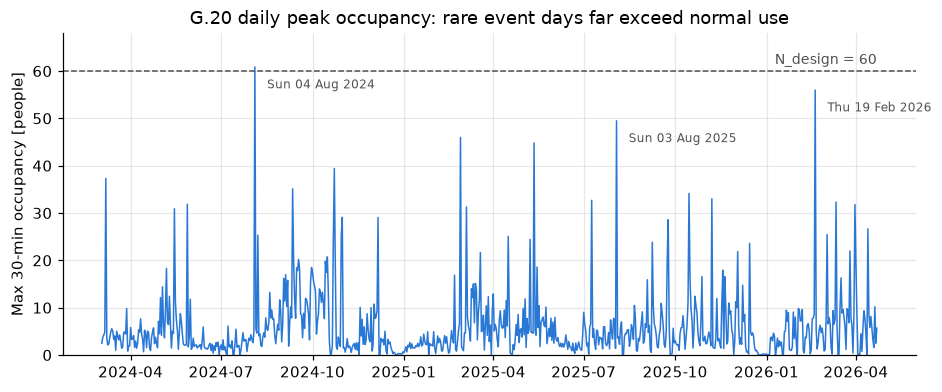

In [2]:
s = pd.Series(occ, index=local)
sustained30 = s.rolling(30).mean()
daily_max = sustained30.resample("D").max()
N_DESIGN = float(np.floor(sustained30.max()))
print(f"Occupancy (1-min means): median {s.median():.1f}, 99th pct {s.quantile(0.99):.1f}, max {s.max():.1f} people")
print(f"Highest 30-min sustained occupancy: {sustained30.max():.1f} people on {sustained30.idxmax():%a %d %b %Y %H:%M}")
print(f"Design occupancy N_design = {N_DESIGN:.0f} people\n")
print("Five busiest days (max 30-min sustained occupancy):")
print(daily_max.sort_values(ascending=False).head(5).round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(daily_max.index, daily_max.values, color=C["blue"], lw=1)
for day in daily_max.sort_values(ascending=False).head(3).index:
    ax.annotate(f"{day:%a %d %b %Y}", xy=(day, daily_max[day]), xytext=(8, -14), textcoords="offset points",
                fontsize=8, color=C["grey"])
ax.axhline(N_DESIGN, color=C["grey"], ls="--", lw=1)
ax.text(daily_max.index[-1], N_DESIGN + 1.5, f"N_design = {N_DESIGN:.0f}", color=C["grey"], fontsize=9, ha="right")
ax.set_ylim(0, N_DESIGN + 8)
ax.set_ylabel("Max 30-min occupancy [people]")
ax.set_title("G.20 daily peak occupancy: rare event days far exceed normal use")
save(fig, "stage4_daily_peak_occupancy")

The busiest days are **Sundays in early August**: 4 Aug 2024 and 3 Aug 2025. These are consistent with Monash's annual Open Day, which is usually held on a Sunday in early August, when crowds use the breakout space. A further spike on Thursday 19 Feb 2026 falls around the start of semester. These event identifications are inferred from the dates, not confirmed. Normal days peak at about 6 people (median daily peak) and rarely exceed 20. The worst case is therefore set by **rare events**, not routine use. This matters for the design decision in Section F.

## B. Compliance at the design rate

A common design basis (AS 1668.2-style default) is **10 L/s of outdoor air per person** at the design occupancy, supplied at a constant rate:

$$Q_{design} = 10 \times N_{design}.$$

In [3]:
Q_DESIGN = 10.0 * N_DESIGN
m_design = evaluate_ventilation(occ, Q_DESIGN, P, DT)
print(f"Q_design = {Q_DESIGN:.0f} L/s  (time constant V/Q = {P.volume_m3 / (Q_DESIGN / 1000) / 60:.1f} min)\n")
for k, v in m_design.items():
    print(f"  {k:28s} {v:10.3f}")

Q_design = 600 L/s  (time constant V/Q = 16.7 min)

  max_8h_mean_ppm                 573.072
  exceeds_8h_limit                  0.000
  margin_8h_ppm                   276.928
  peak_ppm                        888.520
  fraction_above_peak_limit         0.000
  mean_ppm                        427.690


**Result.** At the design rate G.20 complies comfortably: its worst 8-hour mean is far below 850 ppm and it never exceeds 1000 ppm. The question is whether this rate is **much more than needed**. Every litre of outdoor air must be heated or cooled.

## C. The compliance curve F(Q)

Define the **compliance function** for each criterion,

$$F(Q) = \text{metric}\big(C(t;Q)\big) - \text{limit},$$

where the metric is the worst 8-hour mean or the peak over two years. $F>0$ means non-compliant, $F\le 0$ compliant. The minimum ventilation rate is the root $F(Q_{min}) = 0$.

**Why there is exactly one root.** Raising $Q$ can only lower CO2. The sensitivity $S=\partial C/\partial Q$ obeys $V\,dS/dt = (C_{out}-C) - QS$ with $S(0)=0$ and forcing $C_{out}-C \le 0$, so $S\le 0$ always. $F$ is therefore non-increasing (see the `design` module docstring), which is what makes bracketing methods safe.

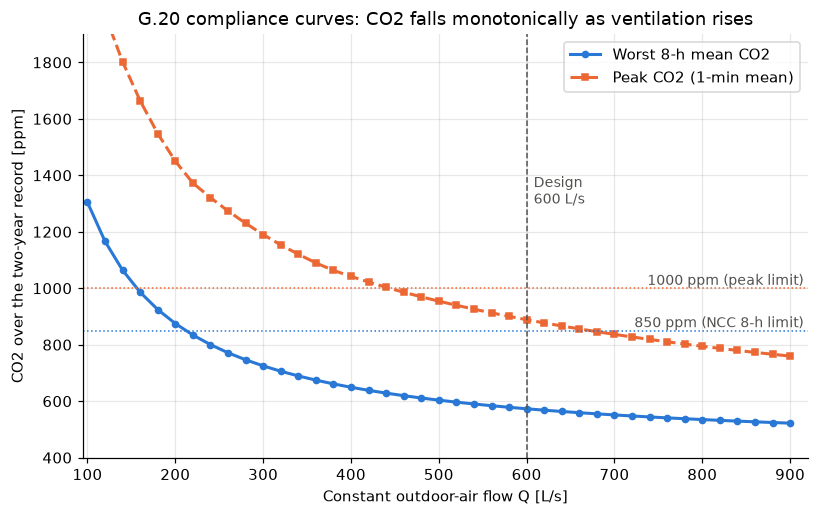

In [4]:
q_sweep = np.linspace(100, 900, 41)
sweep = pd.DataFrame([{"Q": q, **evaluate_ventilation(occ, q, P, DT)} for q in q_sweep])

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(sweep["Q"], sweep["max_8h_mean_ppm"], color=C["blue"], marker="o", markersize=4, label="Worst 8-h mean CO2")
ax.plot(sweep["Q"], sweep["peak_ppm"], color=C["orange"], marker="s", markersize=4, ls="--", label="Peak CO2 (1-min mean)")
ax.axhline(850, color=C["blue"], lw=1, ls=":")
ax.axhline(1000, color=C["orange"], lw=1, ls=":")
ax.text(915, 862, "850 ppm (NCC 8-h limit)", fontsize=9, color=C["grey"], ha="right")
ax.text(915, 1012, "1000 ppm (peak limit)", fontsize=9, color=C["grey"], ha="right")
ax.axvline(Q_DESIGN, color=C["grey"], lw=1, ls="--")
ax.text(Q_DESIGN + 8, 1300, f"Design\n{Q_DESIGN:.0f} L/s", fontsize=9, color=C["grey"])
ax.set_ylim(400, 1900)
ax.set_xlim(95, 920)
ax.set_xlabel("Constant outdoor-air flow Q [L/s]")
ax.set_ylabel("CO2 over the two-year record [ppm]")
ax.set_title("G.20 compliance curves: CO2 falls monotonically as ventilation rises")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 1.0))
save(fig, "stage4_compliance_curve")

## D. Root finding for $Q_{min}$: the shooting method

Finding $Q_{min}$ has the same structure as the **shooting method** (Notebook 9.4): guess a parameter ($Q$), integrate the ODE over the whole record, measure the miss ($F$), and correct the guess. Each $F$ evaluation is a full two-year ODE solve, so the best root finder is the one that needs the fewest evaluations.

| Method | Idea | Convergence |
|---|---|---|
| **Bisection** (own) | Halve a sign-change bracket each step | Linear, error ÷2 per step; always converges |
| **Secant** (own, safeguarded) | Newton's method with the slope taken from the last two iterates (no derivative needed); falls back to bisection if a step would leave the bracket | Superlinear (order ≈ 1.6) near the root |
| **Secant in 1/Q** (own) | The same secant method, but solving for $u = 1/Q$. CO2 above outdoor level scales as $1/Q$ ($C_{ss}-C_{out} = 10^6GN/Q$), so $F$ is nearly a straight line in $u$ and each secant step lands almost on the root | Faster again: a change of variable that linearises the problem |
| **Brent** (`scipy.optimize.brentq`) | Combines bisection, secant and inverse quadratic interpolation | Independent cross-check |

**Convergence criteria:** stop when $|F| \le 0.01$ ppm or the step in $Q$ is $\le 0.01$ L/s. Both are far tighter than the uncertainty in the inputs (Stage 3, Section I).

In [5]:
results = {}
rows = []
for crit in ["8h", "peak"]:
    key, limit = CRITERIA[crit]
    for method, variable in [("bisection", "direct"), ("secant", "direct"), ("secant", "inverse")]:
        r = find_min_ventilation(occ, P, DT, criterion=crit, method=method, variable=variable,
                                 bracket_lps=(50.0, 1000.0))
        results[(crit, r.method)] = r
        rows.append({"criterion": crit, "method": r.method, "Q_min [L/s]": r.root, "F(Q_min) [ppm]": r.f_root,
                     "ODE solves": r.evaluations, "converged": r.converged})
    n_calls = [0]
    def F(q, key=key, limit=limit):
        n_calls[0] += 1
        return evaluate_ventilation(occ, q, P, DT)[key] - limit
    q_b = brentq(F, 50.0, 1000.0, xtol=0.01)
    rows.append({"criterion": crit, "method": "brentq (SciPy)", "Q_min [L/s]": q_b, "F(Q_min) [ppm]": F(q_b),
                 "ODE solves": n_calls[0] - 1, "converged": True})
root_table = pd.DataFrame(rows)
print(root_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Q_MIN_8H = results[("8h", "secant (1/x)")].root
Q_MIN_PEAK = results[("peak", "secant (1/x)")].root
print(f"\nQ_min (8-h NCC) = {Q_MIN_8H:.1f} L/s = {Q_MIN_8H / N_DESIGN:.2f} L/s per design person")
print(f"Q_min (peak)    = {Q_MIN_PEAK:.1f} L/s = {Q_MIN_PEAK / N_DESIGN:.2f} L/s per design person")

criterion         method  Q_min [L/s]  F(Q_min) [ppm]  ODE solves  converged
       8h      bisection     211.8607         -0.0005          17       True
       8h         secant     211.8589          0.0030           9       True
       8h   secant (1/x)     211.8604          0.0000           6       True
       8h brentq (SciPy)     211.8604          0.0000          10       True
     peak      bisection     443.6783          0.0033          17       True
     peak         secant     443.6821         -0.0001          12       True
     peak   secant (1/x)     443.6879         -0.0052           7       True
     peak brentq (SciPy)     443.6820          0.0000           8       True

Q_min (8-h NCC) = 211.9 L/s = 3.53 L/s per design person
Q_min (peak)    = 443.7 L/s = 7.39 L/s per design person


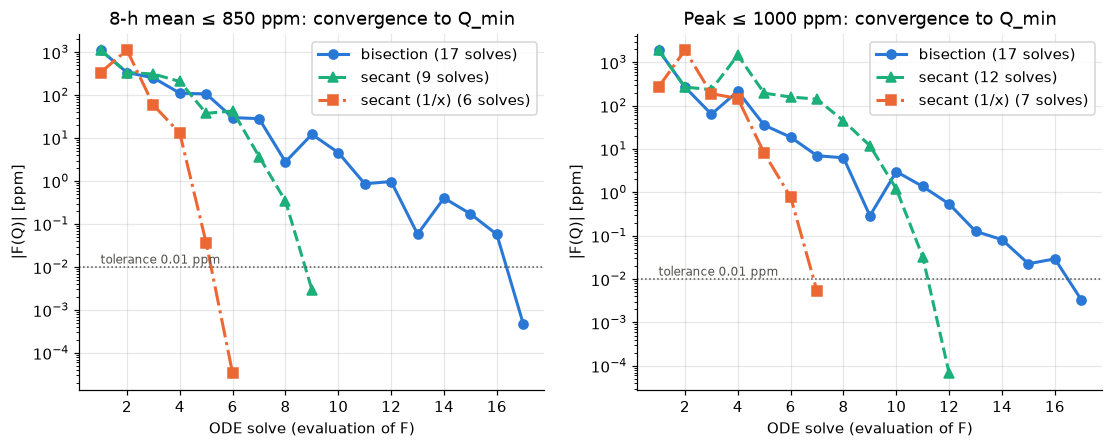

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, crit in zip(axes, ["8h", "peak"]):
    for method, color, marker, ls in [("bisection", C["blue"], "o", "-"), ("secant", C["aqua"], "^", "--"),
                                      ("secant (1/x)", C["orange"], "s", "-.")]:
        r = results[(crit, method)]
        f_hist = np.abs([f for _, f in r.history]) + 1e-6
        ax.semilogy(np.arange(1, len(f_hist) + 1), f_hist, color=color, marker=marker, ls=ls,
                    label=f"{method} ({r.evaluations} solves)")
    ax.axhline(0.01, color=C["grey"], lw=1, ls=":")
    ax.text(1, 0.012, "tolerance 0.01 ppm", fontsize=8, color=C["grey"])
    ax.set_xlabel("ODE solve (evaluation of F)")
    ax.set_ylabel("|F(Q)| [ppm]")
    ax.set_title(f"{'8-h mean ≤ 850 ppm' if crit == '8h' else 'Peak ≤ 1000 ppm'}: convergence to Q_min")
    ax.legend()
save(fig, "stage4_root_convergence")

**What this shows.** All methods agree on $Q_{min}$ to within the tolerance, and SciPy's Brent method confirms it independently.

* **Bisection** halves the bracket each solve: a straight, slowly falling line on the log plot (about 17 solves).
* **The secant method in $Q$** is faster (9–12 solves), but its early steps are slow. $F$ is strongly curved, roughly like $1/Q$, so straight-line (secant) predictions undershoot or overshoot until the iterates are close to the root. Then the error collapses superlinearly.
* **The secant method in $1/Q$** needs the fewest solves (6–7), because the change of variable makes $F$ almost linear and each secant step lands almost on the root. Reformulating a problem to suit the method can matter as much as the method itself.

The bracket safeguard was never needed in these runs, because every secant step stayed inside the bracket. It remains as a guarantee for less well-behaved criteria.

## E. Independent checks of the answer

1. **Tightness:** the criterion should fail just below $Q_{min}$ and pass just above it.
2. **Different solver:** recompute the metric at $Q_{min}$ with the independently verified RK4 solver (Stage 2–3) instead of the exact solution.
3. **Physical bound:** in steady state, $C_{ss} = C_{out} + 10^6 G N / Q$. The worst 8-hour window has a mean occupancy $\bar N_{8h}$, so a quasi-steady estimate is $Q \approx 10^6 G \bar N_{8h} / (850 - C_{out})$. It should be close to, and slightly above, the true $Q_{min}$, because CO2 takes time to build up.

In [7]:
key8 = CRITERIA["8h"][0]
for label, q in [("0.99 x Q_min", 0.99 * Q_MIN_8H), ("Q_min", Q_MIN_8H), ("1.01 x Q_min", 1.01 * Q_MIN_8H)]:
    print(f"{label:13s} Q = {q:7.2f} L/s -> worst 8-h mean = {evaluate_ventilation(occ, q, P, DT)[key8]:8.3f} ppm")

c_rk4 = rk4(occ, Q_MIN_8H, P, DT)
max8_rk4 = np.nanmax(rolling_mean(step_mean_concentration(c_rk4, occ, Q_MIN_8H, P, DT), 480))
print(f"\nRK4 solver at Q_min: worst 8-h mean = {max8_rk4:.4f} ppm (exact solution gives 850 by construction)")

n8 = np.nanmax(rolling_mean(occ, 480))
q_qs = 1e6 * P.co2_generation_lps * n8 / (850 - P.outdoor_co2_ppm)
print(f"Quasi-steady estimate: mean occupancy in the worst 8 h = {n8:.2f} people -> Q = {q_qs:.1f} L/s "
      f"(true Q_min {Q_MIN_8H:.1f} L/s, {100 * (q_qs / Q_MIN_8H - 1):+.1f} %)")

0.99 x Q_min  Q =  209.74 L/s -> worst 8-h mean =  854.265 ppm
Q_min         Q =  211.86 L/s -> worst 8-h mean =  850.000 ppm
1.01 x Q_min  Q =  213.98 L/s -> worst 8-h mean =  845.817 ppm

RK4 solver at Q_min: worst 8-h mean = 850.0000 ppm (exact solution gives 850 by construction)
Quasi-steady estimate: mean occupancy in the worst 8 h = 17.69 people -> Q = 213.9 L/s (true Q_min 211.9 L/s, +1.0 %)


**What this shows.** The criterion switches from fail to pass exactly across $Q_{min}$. The RK4 solver reproduces the metric to a small fraction of a ppm. The quasi-steady estimate lands close to $Q_{min}$ and slightly above it: CO2 needs time to build up, and the room's 47-minute time constant smooths the start of the busy period. The answer is consistent with the physics, not just with the code.

## F. Which days set the design?

$Q_{min}$ is set by the single worst 8-hour period in two years. A designer should know **what** that period was, and **how many days** would fail at lower rates. Section A's data audit already pointed to event days.

 Q [L/s]  days exceeding 850 ppm (8-h) [%]  days exceeding (count)
  100.00                              2.69                      21
  125.00                              1.66                      13
  150.00                              0.64                       5
  175.00                              0.38                       3
  200.00                              0.13                       1
  211.86                              0.13                       1

Worst five days at Q_min (max 8-h mean CO2):
t_utc
2025-05-12 00:00:00+10:00    850.0
2024-10-14 00:00:00+11:00    813.2
2024-08-04 00:00:00+10:00    806.8
2024-09-16 00:00:00+10:00    766.3
2025-08-03 00:00:00+10:00    750.6


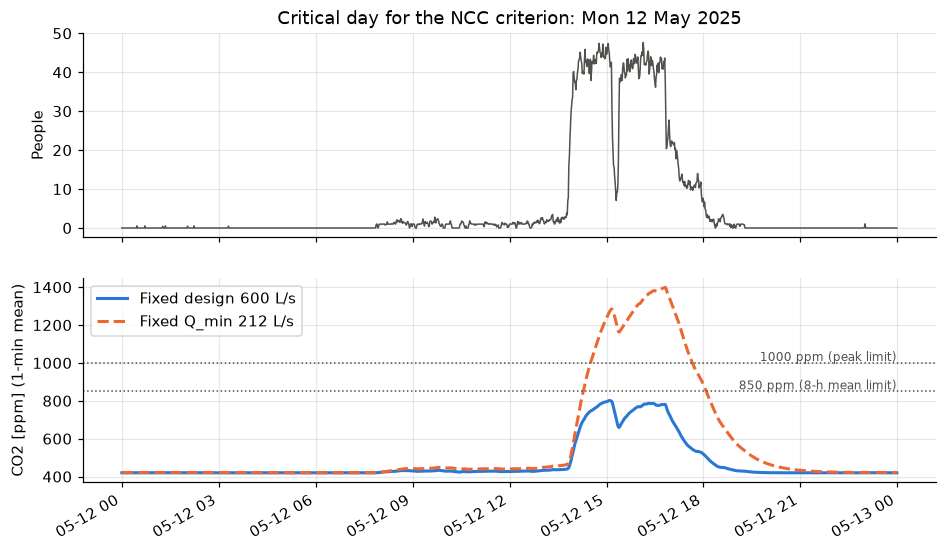

In [8]:
def daily_exceedance(q):
    # Fraction of days whose worst 8-h mean exceeds 850 ppm at constant ventilation q.
    c = exact_solution(occ, q, P, DT)
    r8 = pd.Series(rolling_mean(step_mean_concentration(c, occ, q, P, DT), 480), index=local)
    return (r8.resample("D").max() > 850).mean(), r8

frac_rows = []
for q in [100, 125, 150, 175, 200, Q_MIN_8H]:
    frac, r8 = daily_exceedance(q)
    frac_rows.append({"Q [L/s]": q, "days exceeding 850 ppm (8-h) [%]": 100 * frac,
                      "days exceeding (count)": int(round(frac * r8.resample("D").max().size))})
print(pd.DataFrame(frac_rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

_, r8_min = daily_exceedance(Q_MIN_8H)
worst = r8_min.resample("D").max().sort_values(ascending=False).head(5)
print("\nWorst five days at Q_min (max 8-h mean CO2):")
print(worst.round(1).to_string())

# CO2 on the critical day under three ventilation strategies.
crit_day = worst.index[0]
mask = np.asarray((local >= crit_day) & (local < crit_day + pd.Timedelta(days=1)))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(local[mask], occ[mask], color=C["grey"], lw=1)
ax1.set_ylabel("People")
ax1.set_title(f"Critical day for the NCC criterion: {crit_day:%a %d %b %Y}")
for q, color, ls, label in [(Q_DESIGN, C["blue"], "-", f"Fixed design {Q_DESIGN:.0f} L/s"),
                            (Q_MIN_8H, C["orange"], "--", f"Fixed Q_min {Q_MIN_8H:.0f} L/s")]:
    c = exact_solution(occ, q, P, DT)
    ax2.plot(local[mask], step_mean_concentration(c, occ, q, P, DT)[mask], color=color, ls=ls, label=label)
ax2.axhline(850, color=C["grey"], lw=1, ls=":")
ax2.axhline(1000, color=C["grey"], lw=1, ls=":")
ax2.text(local[mask][-1], 860, "850 ppm (8-h mean limit)", fontsize=8, color=C["grey"], ha="right")
ax2.text(local[mask][-1], 1010, "1000 ppm (peak limit)", fontsize=8, color=C["grey"], ha="right")
ax2.set_ylabel("CO2 [ppm] (1-min mean)")
ax2.legend(loc="upper left")
fig.autofmt_xdate()
save(fig, "stage4_critical_day")

**What this shows.** At $Q_{min}$ exactly one day sits on the limit: **Monday 12 May 2025**, when about 18 people used the room on average over 8 consecutive hours. At half of $Q_{min}$, still only about 3 % of days would exceed the NCC limit. The 8-hour criterion is driven by a few days of *long, sustained* use, whereas the peak criterion is driven by the short, crowded event days found in Section A, such as Open Day. Choosing $Q$ is a genuine **engineering decision**, not just a calculation:

* **Design for the worst observed day** ($Q_{min}$, as in this notebook). This is safe, but it ventilates continuously for a handful of days per year.
* **Design for typical use, and manage exceptional days separately**: boost ventilation for booked events, or open doors. This saves energy, but it relies on operational procedures.

Demand-controlled ventilation (next section) makes this choice unnecessary, because it responds to whatever occupancy actually occurs.

## G. Demand-controlled ventilation (DCV)

DCV supplies outdoor air in proportion to the measured headcount:

$$Q(t) = \max\big(Q_{floor},\; q_p\,N(t)\big).$$

* $q_p$ [L/s per person] is the per-person rate, found by root finding so that the worst 8-hour mean is exactly 850 ppm (secant method).
* $Q_{floor}$ = 50 L/s is a minimum flow (about 0.3 air changes per hour) kept at all times to flush building-related pollutants. It is an assumption, and Stage 5 varies it.

**Theory check.** For a long constant occupancy, $C_{ss} = C_{out} + 10^6 G / q_p$, independent of $N$. The limit then requires $q_p \ge 10^6 G / (850 - C_{out}) = 12.09$ L/s per person. This is the same per-person rate that the NCC's 850 ppm basis implies.

In [9]:
Q_FLOOR = 50.0
r_dcv = find_min_dcv_rate(occ, P, DT, q_floor_lps=Q_FLOOR)
QP = r_dcv.root
q_dcv = dcv_ventilation(occ, QP, Q_FLOOR)
m_dcv = evaluate_ventilation(occ, q_dcv, P, DT)
qp_theory = 1e6 * P.co2_generation_lps / (850 - P.outdoor_co2_ppm)
print(f"DCV per-person rate q_p = {QP:.3f} L/s per person ({r_dcv.evaluations} ODE solves, secant); "
      f"steady-state theory {qp_theory:.3f}")
print(f"DCV: worst 8-h mean {m_dcv['max_8h_mean_ppm']:.1f} ppm, peak {m_dcv['peak_ppm']:.1f} ppm, "
      f"mean {m_dcv['mean_ppm']:.1f} ppm; mean flow {q_dcv.mean():.1f} L/s, max flow {q_dcv.max():.0f} L/s")

# Same controller, but the fan cannot exceed the 600 L/s design capacity.
r_cap = find_min_dcv_rate(occ, P, DT, q_floor_lps=Q_FLOOR, q_cap_lps=Q_DESIGN)
QP_CAP = r_cap.root
q_dcv_cap = dcv_ventilation(occ, QP_CAP, Q_FLOOR, Q_DESIGN)
m_cap = evaluate_ventilation(occ, q_dcv_cap, P, DT)
print(f"\nDCV capped at {Q_DESIGN:.0f} L/s: q_p = {QP_CAP:.3f} L/s per person; worst 8-h mean "
      f"{m_cap['max_8h_mean_ppm']:.1f} ppm, peak {m_cap['peak_ppm']:.1f} ppm; cap active "
      f"{100 * np.mean(q_dcv_cap >= Q_DESIGN):.3f} % of the time")

DCV per-person rate q_p = 12.064 L/s per person (10 ODE solves, secant); steady-state theory 12.093
DCV: worst 8-h mean 850.0 ppm, peak 851.0 ppm, mean 495.9 ppm; mean flow 52.5 L/s, max flow 822 L/s

DCV capped at 600 L/s: q_p = 12.064 L/s per person; worst 8-h mean 850.0 ppm, peak 929.1 ppm; cap active 0.011 % of the time


**What this shows.** The per-person rate found from the real occupancy data almost equals the steady-state theory value. Under DCV, every sustained occupied period settles towards the same CO2 level ($C_{out} + 10^6 G / q_p$), so the binding condition is simply a long busy period. DCV meets **both** criteria: the peak stays just above 850 ppm, well below 1000. Its average CO2 is higher than with fixed ventilation, because it stops over-ventilating when the room is lightly used. That is the point: air quality is held at the target instead of far below it.

**Hardware caveat.** Uncapped DCV would need about 820 L/s on Open Day, which is *more* than the 600 L/s design capacity. So the per-person rate is re-solved below with the fan capped at the design flow.

## H. Outdoor air and energy comparison

Every cubic metre of outdoor air must be brought to indoor temperature. The sensible conditioning energy is

$$E = \rho c_p \,\Delta T \int Q\,dt,$$

with $\rho c_p = 1.206$ kJ/(m³K). Because $Q$ is constant within each minute, $\int Q\,dt = \sum Q_i\,\Delta t$ exactly (the rectangle rule is exact for a piecewise-constant integrand, Week 6).

**Assumption:** a representative indoor–outdoor temperature difference of $\Delta T$ = 7 K. Melbourne's mean annual temperature is about 15 °C, against an indoor setpoint of 21–24 °C. No outdoor temperature data were supplied. Energy is proportional to $\Delta T$, so the **percentage savings do not depend on this assumption**.

Scenarios (all simulated over the full record, then scaled to one year):

1. **Fixed design**, $Q_{design}$ continuously (24/7).
2. **Fixed $Q_{min}$ (peak)**, the smallest constant rate meeting both criteria, 24/7.
3. **Fixed $Q_{min}$ (8-h)**, the smallest constant rate meeting the NCC criterion only, 24/7.
4. **Scheduled fixed**, $Q_{min}$ (peak) from 06:00 to 22:00 daily and $Q_{floor}$ overnight. 96.6 % of person-time falls in these hours.
5. **DCV**, $Q = \max(50, q_p N)$, uncapped.
6. **DCV capped** at the 600 L/s design fan capacity.

Delta T = 7.0 K; record scaled to one year by x0.468

                  scenario  worst 8-h [ppm]  peak [ppm]  NCC 8-h OK  peak OK  air [Mm3/yr]  energy [MWh/yr]  saving vs design [%]
      1. Fixed design 24/7           573.07      888.52        True     True         18.93            44.40                  0.00
2. Fixed Q_min (peak) 24/7           626.81      999.99        True     True         14.00            32.83                 26.05
 3. Fixed Q_min (8-h) 24/7           850.00     1398.95        True    False          6.69            15.68                 64.69
        4. Scheduled 06-22           665.28      999.99        True     True          9.86            23.12                 47.92
                    5. DCV           850.00      851.02        True     True          1.66             3.89                 91.24
  6. DCV capped at 600 L/s           850.00      929.09        True     True          1.66             3.89                 91.25


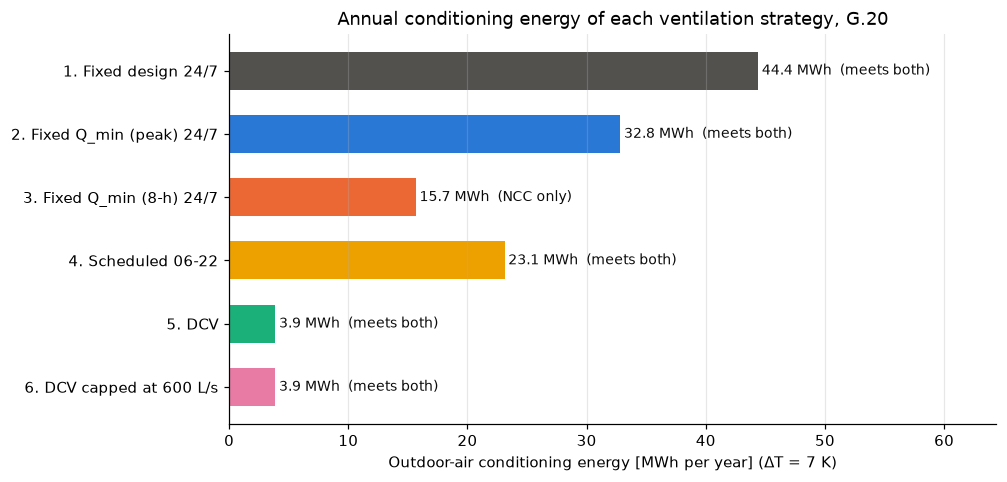

In [10]:
DELTA_T = 7.0
hour = local.hour
day_hours = (hour >= 6) & (hour < 22)
scenarios = {
    "1. Fixed design 24/7":        np.full(N_STEPS, Q_DESIGN),
    "2. Fixed Q_min (peak) 24/7":  np.full(N_STEPS, Q_MIN_PEAK),
    "3. Fixed Q_min (8-h) 24/7":   np.full(N_STEPS, Q_MIN_8H),
    "4. Scheduled 06-22":          np.where(day_hours, Q_MIN_PEAK, Q_FLOOR),
    "5. DCV":                      q_dcv,
    "6. DCV capped at 600 L/s":    q_dcv_cap,
}
rows = []
for name, q in scenarios.items():
    m = evaluate_ventilation(occ, q if np.ptp(q) > 0 else float(q[0]), P, DT)
    e = outdoor_air_energy(q, DT, N_STEPS, DELTA_T)
    rows.append({"scenario": name,
                 "worst 8-h [ppm]": m["max_8h_mean_ppm"], "peak [ppm]": m["peak_ppm"],
                 "NCC 8-h OK": m["max_8h_mean_ppm"] <= 850.05, "peak OK": m["peak_ppm"] <= 1000.05,
                 "air [Mm3/yr]": e["air_volume_m3"] * TO_ANNUAL / 1e6,
                 "energy [MWh/yr]": e["energy_kwh"] * TO_ANNUAL / 1000})
energy = pd.DataFrame(rows)
base = energy.loc[0, "energy [MWh/yr]"]
energy["saving vs design [%]"] = 100 * (1 - energy["energy [MWh/yr]"] / base)
print(f"Delta T = {DELTA_T} K; record scaled to one year by x{TO_ANNUAL:.3f}\n")
print(energy.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [C["grey"], C["blue"], C["orange"], C["yellow"], C["aqua"], C["magenta"]]
bars = ax.barh(energy["scenario"][::-1], energy["energy [MWh/yr]"][::-1], color=colors[::-1], height=0.6)
for bar, (_, row) in zip(bars, energy[::-1].iterrows()):
    ok = "meets both" if (row["NCC 8-h OK"] and row["peak OK"]) else ("NCC only" if row["NCC 8-h OK"] else "fails NCC")
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{row['energy [MWh/yr]']:.1f} MWh  ({ok})", va="center", fontsize=9, color=C["ink"])
ax.set_xlabel(f"Outdoor-air conditioning energy [MWh per year] (ΔT = {DELTA_T:.0f} K)")
ax.set_title("Annual conditioning energy of each ventilation strategy, G.20")
ax.set_xlim(0, energy["energy [MWh/yr]"].max() * 1.45)
ax.grid(axis="y", visible=False)
save(fig, "stage4_energy")

## I. Engineering interpretation and limitations

**Findings for G.20 (under the stated assumptions):**

1. A conventional constant design rate ($10$ L/s × 60 people = 600 L/s) **easily meets** both CO2 criteria, but **over-ventilates** most of the time. The room is empty or lightly used for most hours.
2. The smallest constant rate meeting the **NCC 8-hour limit** is only about **35 %** of the design rate. Meeting the stricter **1000 ppm peak** needs about **74 %** of it.
3. These minimum rates are set by a few **exceptional days**: one day of long sustained use for the 8-hour criterion, and crowded event days such as Open Day for the peak. Designing for them, or managing them operationally, is a real engineering trade-off.
4. **Demand-controlled ventilation** meets both criteria with roughly **12 L/s per person**, and cuts outdoor-air conditioning energy by **about 90 %** compared with the fixed design rate. This holds even with the fan capped at the existing design capacity. A scheduled constant rate captures only about half of that saving.
5. **Numerically**, finding $Q_{min}$ is a shooting-type root-finding problem. Solving for $1/Q$ instead of $Q$ linearises it and cuts the number of full two-year simulations from about 17 (bisection) to 6–7 (secant).

**Limitations (what this analysis cannot establish):**

* **No measured CO2.** The model is verified (Stage 3), but not validated against real air in G.20.
* **Room volume is estimated** (600 m³). $V$ does not change steady-state CO2, so $Q_{min}$ for the 8-hour criterion is only weakly sensitive to it. The peak criterion is more sensitive (Stage 5).
* **Idealised DCV.** It responds instantly and exactly to the sensor count. Real controllers lag, and real fans have minimum speeds. A people-counter error goes straight into under- or over-ventilation.
* **Energy** uses one representative $\Delta T$. It ignores heat recovery, fan energy, latent loads and economy-cycle ("free") cooling. The *percentage* savings are robust; the absolute MWh are indicative only.
* **Well-mixed assumption.** Short-circuiting of supply air, or stratification, would raise the CO2 in the occupied zone above the model's prediction.
* **Space-ID mapping** of G.20 is taken from a workbook sheet labelled "Incorrect Data". If it is wrong, the results apply to a different room.